In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("data/processed/customer_features.csv")
df.head()

,CustomerID,last_purchase_date,first_purchase_date,frequency,monetary,total_items,product_variety,recency,tenure_days,avg_order_value,coffee_beans_share,brew_gear_share,accessories_share,monetary_log,frequency_log,avg_order_value_log,tenure_days_log
0,CUST_0001,2026-08-30,2026-06-12,2,74.5,4,2,78,157,37.250000,0.885906,0.000000,0.114094,4.324133,1.098612,3.644144,5.062595
1,CUST_0002,2026-10-03,2025-12-19,4,194.0,5,4,44,332,48.500000,0.561856,0.438144,0.000000,5.273000,1.609438,3.901973,5.808142
2,CUST_0003,2026-10-22,2026-10-22,1,60.5,3,2,25,25,60.500000,1.000000,0.000000,0.000000,4.119037,0.693147,4.119037,3.258097
3,CUST_0004,2026-09-02,2026-01-15,12,392.5,17,6,75,305,32.708333,0.636943,0.071338,0.291720,5.975081,2.564949,3.517745,5.723585
4,CUST_0005,2026-04-22,2025-12-23,6,325.0,12,5,208,328,54.166667,0.887692,0.086154,0.026154,5.786897,1.945910,4.010359,5.796058


In [3]:
#Dataset Overview
print(df.shape)

(1197, 17)


In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CustomerID           1197 non-null   str    
 1   last_purchase_date   1197 non-null   str    
 2   first_purchase_date  1197 non-null   str    
 3   frequency            1197 non-null   int64  
 4   monetary             1197 non-null   float64
 5   total_items          1197 non-null   int64  
 6   product_variety      1197 non-null   int64  
 7   recency              1197 non-null   int64  
 8   tenure_days          1197 non-null   int64  
 9   avg_order_value      1197 non-null   float64
 10  coffee_beans_share   1197 non-null   float64
 11  brew_gear_share      1197 non-null   float64
 12  accessories_share    1197 non-null   float64
 13  monetary_log         1197 non-null   float64
 14  frequency_log        1197 non-null   float64
 15  avg_order_value_log  1197 non-null   float64
 16 

In [5]:
print(df.describe().T)

                      count        mean         std       min         25%  \
frequency            1197.0    4.978279    4.420558  1.000000    2.000000   
monetary             1197.0  237.174185  232.041761  8.500000   82.000000   
total_items          1197.0    7.812865    7.434445  1.000000    3.000000   
product_variety      1197.0    3.697577    1.870499  1.000000    2.000000   
recency              1197.0   90.253133   90.702619  1.000000   19.000000   
tenure_days          1197.0  286.959900   85.973629  1.000000  251.000000   
avg_order_value      1197.0   47.086588   21.813869  8.500000   32.312500   
coffee_beans_share   1197.0    0.640414    0.286641  0.000000    0.450122   
brew_gear_share      1197.0    0.280032    0.270642  0.000000    0.000000   
accessories_share    1197.0    0.079554    0.169028  0.000000    0.000000   
monetary_log         1197.0    5.036053    0.998705  2.251292    4.418841   
frequency_log        1197.0    1.579460    0.623750  0.693147    1.098612   

In [6]:
#check for null values
df.isnull().sum()

CustomerID             0
last_purchase_date     0
first_purchase_date    0
frequency              0
monetary               0
total_items            0
product_variety        0
recency                0
tenure_days            0
avg_order_value        0
coffee_beans_share     0
brew_gear_share        0
accessories_share      0
monetary_log           0
frequency_log          0
avg_order_value_log    0
tenure_days_log        0
dtype: int64

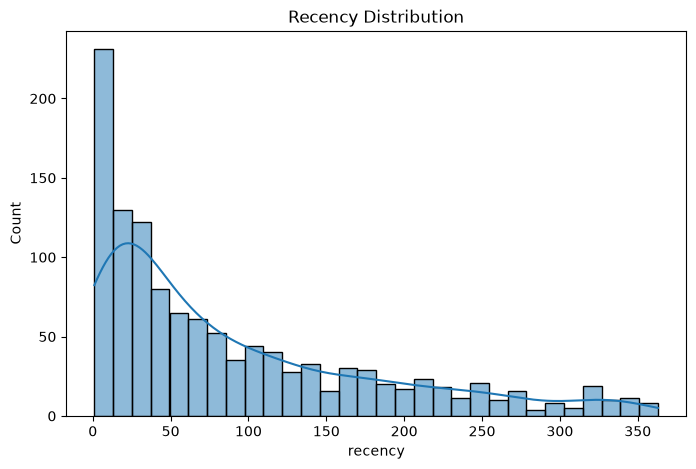

In [7]:
#Univariate Analysis
#Recency Distribution
plt.figure(figsize=(8,5))
sns.histplot(df['recency'], bins=30, kde=True)
plt.title("Recency Distribution")
plt.show()

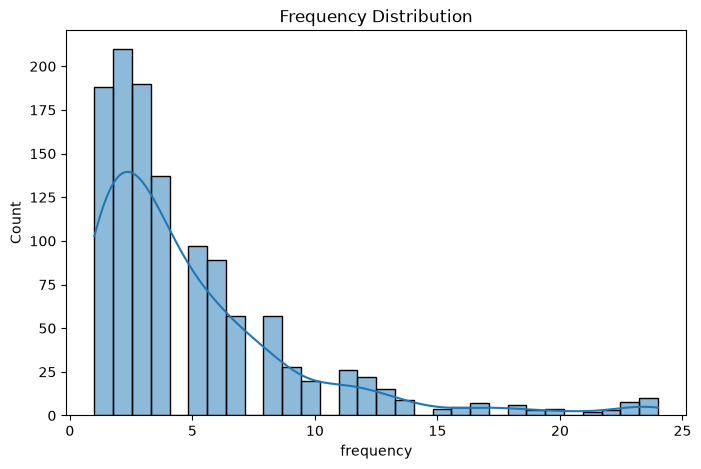

In [8]:
#Frequency Distribution
plt.figure(figsize=(8,5))
sns.histplot(df['frequency'], bins=30, kde=True)
plt.title("Frequency Distribution")
plt.show()

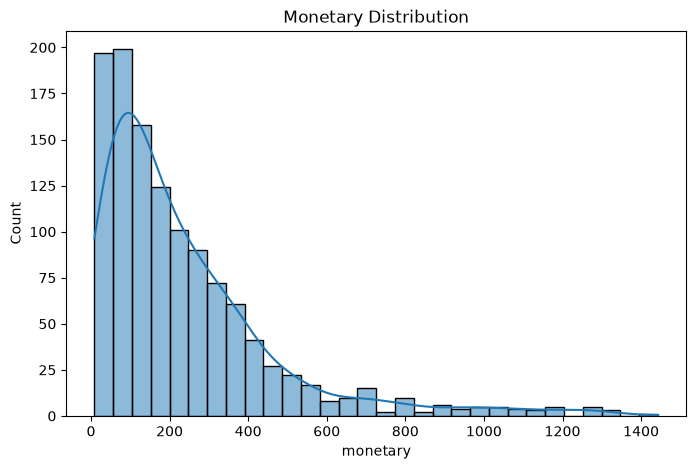

In [9]:
#Monetary Distribution
plt.figure(figsize=(8,5))
sns.histplot(df['monetary'], bins=30, kde=True)
plt.title("Monetary Distribution")
plt.show()

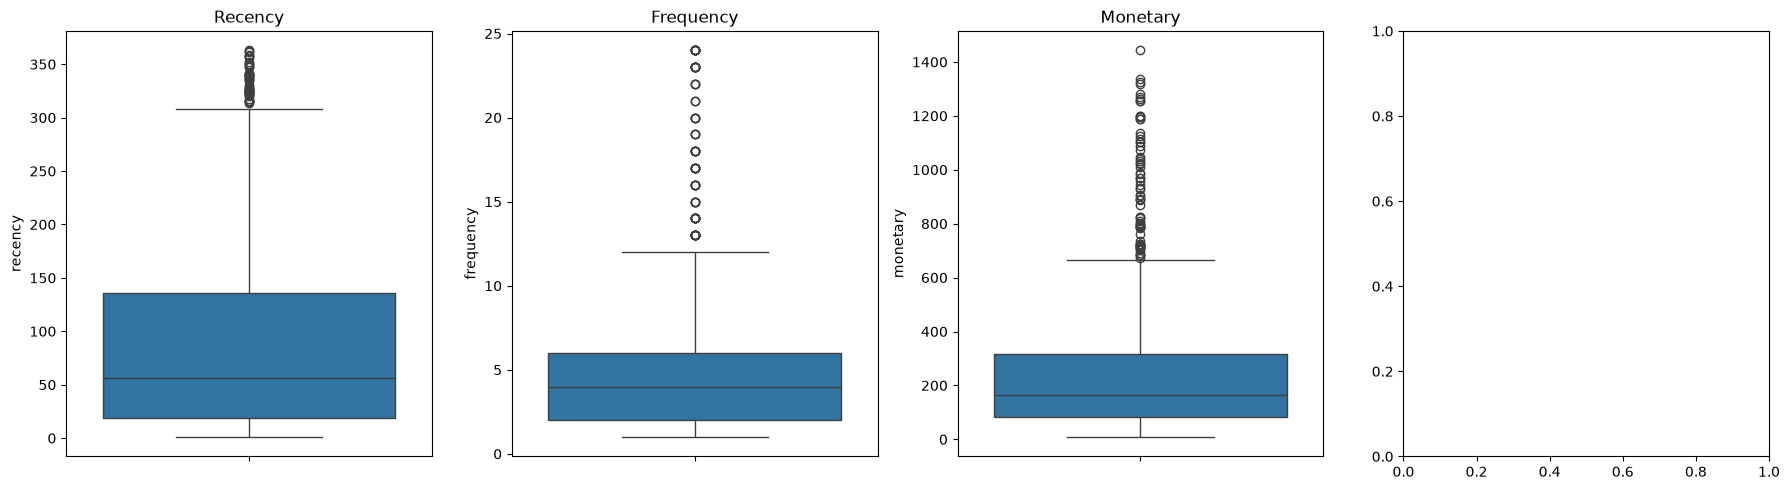

In [10]:
#Outlier Detection
fig, axes = plt.subplots(1,4, figsize=(18,5))

sns.boxplot(y=df['recency'], ax=axes[0])
axes[0].set_title('Recency')

sns.boxplot(y=df['frequency'], ax=axes[1])
axes[1].set_title('Frequency')

sns.boxplot(y=df['monetary'], ax=axes[2])
axes[2].set_title('Monetary')

plt.tight_layout()
plt.show()

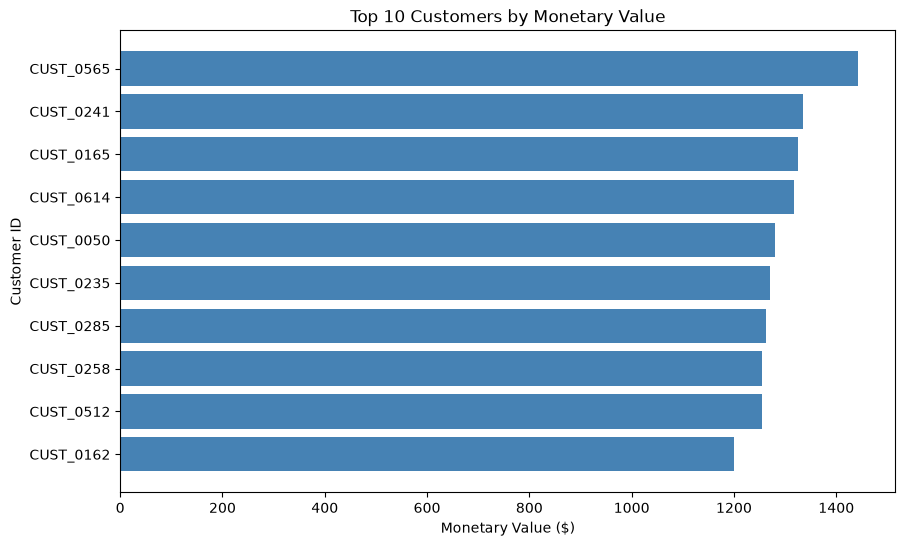

In [11]:
#5. Customer Behavior Analysis
#Top Customers by Revenue
top_customers = df.sort_values(
    by="monetary",
    ascending=False
).head(10)

top_customers[['CustomerID','monetary']]
plt.figure(figsize=(10, 6))
plt.barh(top_customers['CustomerID'].astype(str), top_customers['monetary'], color='steelblue')
plt.xlabel('Monetary Value ($)')
plt.ylabel('Customer ID')
plt.title('Top 10 Customers by Monetary Value')
plt.gca().invert_yaxis()  # Puts the highest spender at the top
plt.show()

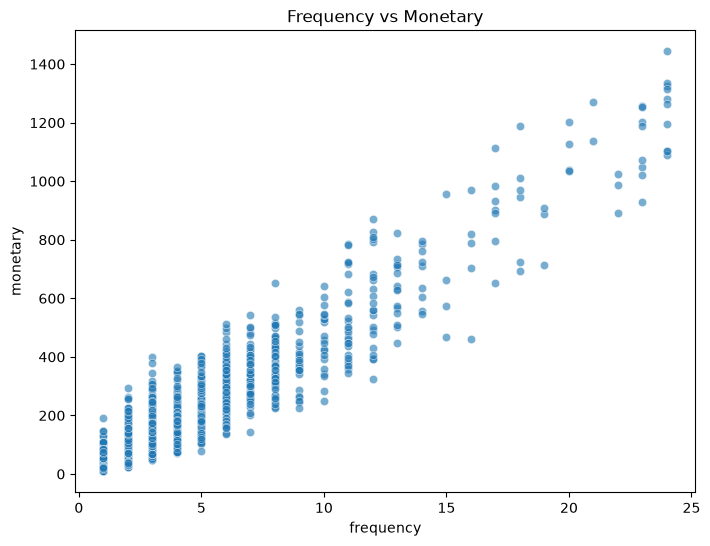

In [13]:
#Frequency vs Monetary
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x='frequency',
    y='monetary',
    alpha=0.6
)

plt.title("Frequency vs Monetary")
plt.show()

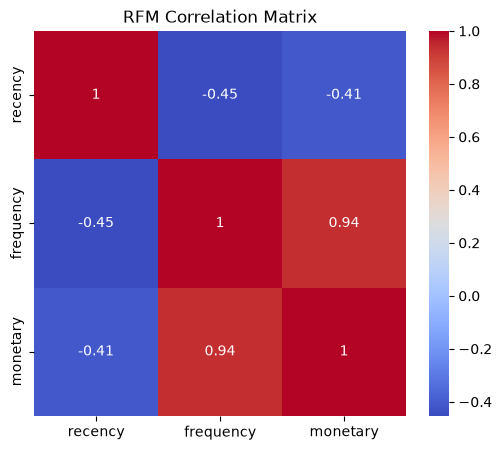

In [15]:
#Correlation Analysis
corr = df[['recency','frequency','monetary']].corr()
plt.figure(figsize=(6,5))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title("RFM Correlation Matrix")
plt.show()

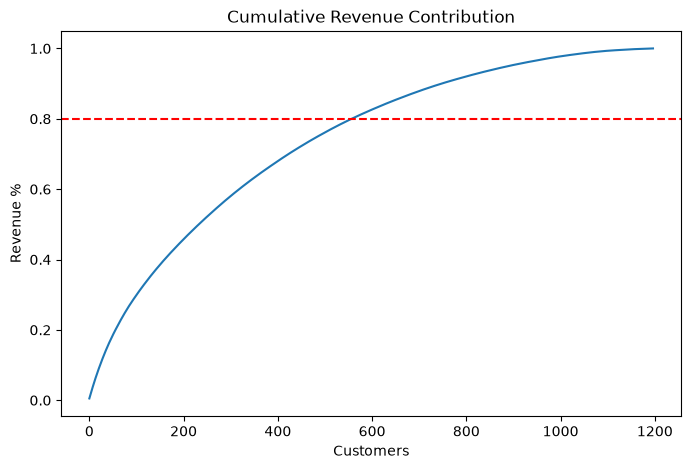

In [19]:
revenue_pct = (
    df['monetary']
    .sort_values(ascending=False)
    .cumsum()
    / df['monetary'].sum()
)

plt.figure(figsize=(8,5))
plt.plot(revenue_pct.values)

plt.axhline(
    y=0.8,
    color='red',
    linestyle='--'
)

plt.title("Cumulative Revenue Contribution")
plt.xlabel("Customers")
plt.ylabel("Revenue %")
plt.show()

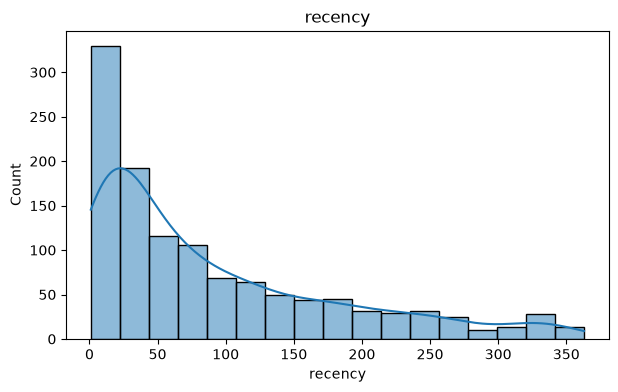

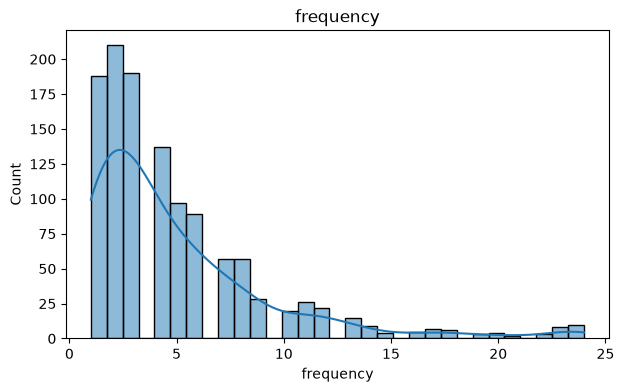

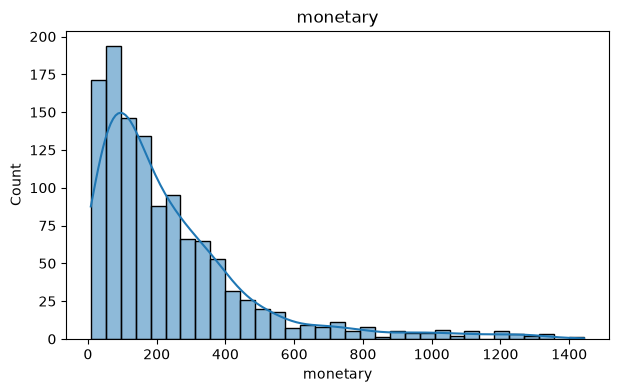

In [21]:
selected_features = ['recency','frequency','monetary']

for feature in selected_features:
    plt.figure(figsize=(7,4))
    sns.histplot(df[feature], kde=True)
    plt.title(feature)
    plt.show()

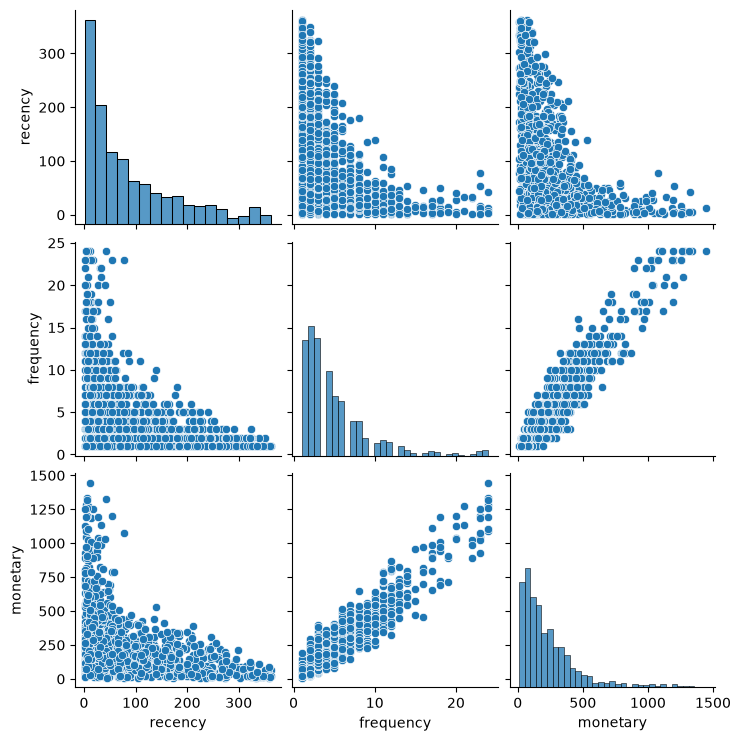

In [23]:
sns.pairplot(
    df[['recency','frequency','monetary']]
)
plt.show()